# La Paradoja de la Supervivencia (La más compleja)

**Hipótesis: "Los Almacenes 'Híbridos' (Antigüedad > 15 años + Adopción Digital Alta) reportan una estabilidad de ventas superior incluso a la de los Almacenes 'Nuevos Nativos' (Antigüedad < 3 años)."**

La Lógica: Esta desafía la idea de que "lo nuevo es mejor". Plantea que la combinación ganadora es Experiencia + Tecnología. Un almacén viejo que se moderniza es imbatible porque tiene clientes leales Y eficiencia moderna.

Cómo cumple con todo:

Regresión: Una regresión logística multinomial prediciendo la categoría "Ventas Estables/Mejores".

Machine Learning: Un Árbol de Decisión para visualizar si la rama de "Viejos + Tech" tiene la tasa más alta de éxito (hoja más pura).

**Almacenes y sus lugares, investigarlo**

In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Mark\Downloads\dataset_limpio_final.csv")
df

,Progress,Finished,Recorded Date,Response ID,Nombre del comercio,Tipo de negocio,¿El negocio tiene reja para entrar? (¿los consumidores pueden entrar a la tienda para escoger y comprar los productos?),¿Cuál fue el año de apertura del negocio?,¿Cuántas personas trabajaron en este negocio (con o sin paga) durante el mes anterior?,¿Cuántas personas trabajaron con un salario fijo durante el último mes?,...,¿Cuál fue el consumo energético del negocio el mes pasado en Kw?,Sexo de la persona encuestada,WhatsApp del la persona entrevistada (Recomendado para la siguiente fase y entrega de reporte final),¿El local de su negocio es rentado o propio?,¿Cuál es el máximo grado de educación de la persona entrevistada?,¿Cuál es la edad de la persona entrevistada?,latitud,longitud,ano_numerico,Decada
0,100,True,10/2/2025 14:27,R_1IIdCNJ8zwPVCZb,Desconocido,Almacén,No,1980,1,0,...,Desconocido,Mujer,77124645,Propio,Primaria,Más de 60,-34.770292,-58.222781,1980,80s
1,100,True,10/4/2025 7:46,R_6nx4McRsbAx4Hu7,Desconocido,Pescadería,No,2024,1,0,...,1012,Mujer,1150081170,Propio,Universidad y más,De 51 a 60,-34.577490,-58.430476,2024,2020s
2,100,True,10/4/2025 8:06,R_1fHu9kpBWusHc0C,Desconocido,Dietéticas,No,1980,2,0,...,no sabe,Hombre,1132652189,Rentado,Universidad y más,Más de 60,-34.577034,-58.430847,1980,80s
3,100,True,10/4/2025 8:23,R_3m2UzzPCRooCx2I,Desconocido,Confitería o Panadería,No,1989,4,4,...,No sabe,Mujer,1126320744,Propio,Secundaria,De 51 a 60,-34.577045,-58.430689,1989,80s
4,100,True,10/4/2025 8:44,R_7zvbUlEW6KNAeOH,Desconocido,Almacén,No,2022,5,5,...,No lo sabe,Hombre,1126651956,Rentado,Secundaria,De 31 a 40,-34.577924,-58.429384,2022,2020s
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
838,100,True,10/28/2025 6:39,R_7U6kdekcXcSPLIB,Atelier Fuerza,Cafeterías,No,2023,3,3,...,No sabe,Mujer,1137027531,Rentado,Universidad y más,De 31 a 40,-34.563491,-58.452454,2023,2020s
839,100,True,10/28/2025 6:52,R_3Pu3LCPfJU3tlix,El kiosko de Alejo,Kiosko,No,1993,2,2,...,No sabe,Hombre,1139464665,Propio,Preparatoria,De 51 a 60,-34.564366,-58.453064,1993,90s
840,100,True,10/28/2025 10:56,R_6OZRCIcyatPqm5I,Donut makers bakery,Cafeterías,No,2025,4,0,...,1690 kWh,Mujer,1171167236,Rentado,Universidad y más,De 41 a 50,NaN,NaN,2025,2020s
841,100,True,10/28/2025 11:19,R_3awtfVIv3lhLU4j,Naymi,Almacén,No,2015,6,6,...,3240,Mujer,.,Rentado,Secundaria,De 41 a 50,-34.600912,-58.374100,2015,2010s


In [2]:
import pandas as pd
import numpy as np

# 1. Filtrar solo "Almacenes"
#    Usamos str.contains para capturar "Almacén", "Almacen", "Mini mercado", etc. si existieran.
#    Ajusta el string 'Almacén' si tu categoría tiene otro nombre exacto.
col_tipo = 'Tipo de negocio'
df_almacenes = df[df[col_tipo].astype(str).str.contains('Almacén', case=False, na=False)].copy()

print(f"--- Paso 1: Filtrado ---")
print(f"Total de negocios originales: {len(df)}")
print(f"Total de Almacenes encontrados: {len(df_almacenes)}")

# 2. Ingeniería de Variables: Calcular Antigüedad
col_ano = '¿Cuál fue el año de apertura del negocio?'
col_adopcion = '¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)'

#    A. Limpiar año y calcular edad (Referencia: 2025 según tu archivo)
df_almacenes['Ano_Num'] = pd.to_numeric(df_almacenes[col_ano], errors='coerce')
df_almacenes = df_almacenes.dropna(subset=['Ano_Num']) # Borramos si no sabemos el año
df_almacenes['Antiguedad'] = 2025 - df_almacenes['Ano_Num']

#    B. Simplificar Adopción a Binario (Alta/Mod vs. Baja/Ninguna) para la segmentación
def es_tech_avanzado(texto):
    if not isinstance(texto, str): return False
    t = texto.lower()
    # Consideramos "Avanzado" si es Alto o Moderado
    return 'alto' in t or 'moderado' in t

df_almacenes['Es_Tech'] = df_almacenes[col_adopcion].apply(es_tech_avanzado)

# 3. Creación de Perfiles (La Lógica de la Hipótesis)
#    Definimos las reglas de negocio para cada grupo:
condiciones = [
    (df_almacenes['Antiguedad'] <= 5),  # Nativos: Nuevos (< 5 años) sin importar tecno
    (df_almacenes['Antiguedad'] > 15) & (df_almacenes['Es_Tech'] == True),  # Híbridos: Viejos (> 15) + Tech
    (df_almacenes['Antiguedad'] > 15) & (df_almacenes['Es_Tech'] == False)  # Tradicionales: Viejos (> 15) + No Tech
]
# Etiquetas correspondientes
etiquetas = ['Nativo (Nuevo)', 'Híbrido (Viejo+Tech)', 'Tradicional (Viejo-NoTech)']

# Aplicamos la lógica (los que no cumplen ninguna quedan como "Transición")
df_almacenes['Perfil_Estrategico'] = np.select(condiciones, etiquetas, default='Transición (Medio)')

# 4. Verificación de Resultados
print(f"\n--- Paso 2: Segmentación de Perfiles ---")
conteo_perfiles = df_almacenes['Perfil_Estrategico'].value_counts()
print(conteo_perfiles)

#    Verificamos con un ejemplo visual de las columnas nuevas
print(f"\n--- Muestra de Datos Generados ---")
cols_mostrar = ['Ano_Num', 'Antiguedad', col_adopcion, 'Perfil_Estrategico']
print(df_almacenes[cols_mostrar].head(5))

--- Paso 1: Filtrado ---
Total de negocios originales: 843
Total de Almacenes encontrados: 159

--- Paso 2: Segmentación de Perfiles ---
Perfil_Estrategico
Nativo (Nuevo)                68
Transición (Medio)            42
Híbrido (Viejo+Tech)          36
Tradicional (Viejo-NoTech)    13
Name: count, dtype: int64

--- Muestra de Datos Generados ---
    Ano_Num  Antiguedad  \
0      1980          45   
4      2022           3   
10     2024           1   
11     2015          10   
12     2022           3   

   ¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)  \
0                                              Básico                                                     
4                                            Moderado                                                     
10                                           Moderado                                                     
11                                           Moderado      

In [3]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Preparar el Target (Variable Objetivo: Éxito en Ventas)
col_ventas = '¿Tus ventas actuales están mejor, peor o igual en comparación con las de hace un mes?'
# Consideramos éxito si son "Mejor" o "Igual" (Estabilidad), para ser más justos con los viejos.
# Si prefieres solo "Mejor", cambia la condición a: x == 'Mejor'
df_almacenes['Exito_Ventas'] = df_almacenes[col_ventas].apply(lambda x: 1 if x == 'Mejor' or x == 'Igual' else 0)

# 2. Preparar las Variables Predictoras
#    Convertimos el booleano 'Es_Tech' a número (1/0)
df_almacenes['Es_Tech_Num'] = df_almacenes['Es_Tech'].astype(int)

#    ¡EL PASO CLAVE! Creamos el Término de Interacción (Edad x Tecnología)
#    Esto le dice al modelo: "Mira cómo cambia el efecto de la edad cuando hay tecnología".
df_almacenes['Interaccion'] = df_almacenes['Antiguedad'] * df_almacenes['Es_Tech_Num']

# 3. Definir y Entrenar el Modelo de Regresión Logística
#    Usamos statsmodels porque te da el reporte estadístico académico (p-values)
X = df_almacenes[['Antiguedad', 'Es_Tech_Num', 'Interaccion']]
X = sm.add_constant(X) # Agregamos la constante (intercepto) necesaria para la regresión
y = df_almacenes['Exito_Ventas']

try:
    model_logit = sm.Logit(y, X).fit()
    print(model_logit.summary())
    
    # 4. Interpretación Automática de los Coeficientes
    coef_edad = model_logit.params['Antiguedad']
    coef_interaccion = model_logit.params['Interaccion']
    
    print("\n--- INTERPRETACIÓN DE LA PARADOJA ---")
    print(f"1. Efecto de la Edad (solo): {coef_edad:.4f}")
    if coef_edad < 0:
        print("   -> (Negativo) Confirma que, por sí sola, la antigüedad tiende a bajar el rendimiento.")
    else:
        print("   -> (Positivo) La antigüedad por sí sola no parece ser mala.")
        
    print(f"2. Efecto de la Interacción (El Escudo): {coef_interaccion:.4f}")
    if coef_interaccion > 0:
        print("   -> (Positivo) ¡ÉXITO! La interacción es positiva.")
        print("      Esto significa que la tecnología 'frena' o invierte el efecto negativo de la edad.")
        print("      Cuanto más tecnológico es el almacén, menos importa que sea viejo.")
    else:
        print("   -> (Negativo) No se observa el efecto amortiguador esperado.")

except Exception as e:
    print(f"Ocurrió un error al ajustar el modelo (posiblemente pocos datos): {e}")

Optimization terminated successfully.
         Current function value: 0.617785
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:           Exito_Ventas   No. Observations:                  159
Model:                          Logit   Df Residuals:                      155
Method:                           MLE   Df Model:                            3
Date:                Mon, 24 Nov 2025   Pseudo R-squ.:                 0.02259
Time:                        19:39:54   Log-Likelihood:                -98.228
converged:                       True   LL-Null:                       -100.50
Covariance Type:            nonrobust   LLR p-value:                    0.2086
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.1056      0.442      0.239      0.811      -0.762       0.973
Antiguedad      0.0163    

C:\Users\Mark\AppData\Local\Temp\ipykernel_19032\3117260299.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


✅ ¡Imagen guardada exitosamente en: C:\Users\Mark\Downloads\grafico_paradoja_almacenes.png


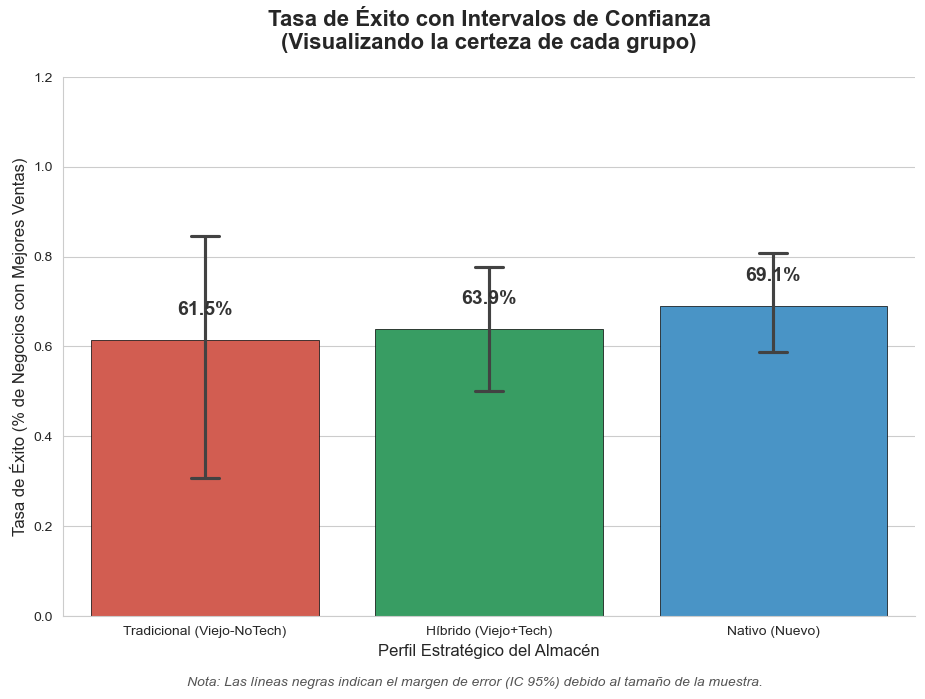

In [8]:
import os

# 1. Configuración Visual
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# 2. Preparar los Datos
perfiles_clave = ['Tradicional (Viejo-NoTech)', 'Híbrido (Viejo+Tech)', 'Nativo (Nuevo)']
df_grafico = df_almacenes[df_almacenes['Perfil_Estrategico'].isin(perfiles_clave)].copy()

# 3. Colores
colores_perfil = {
    'Tradicional (Viejo-NoTech)': '#e74c3c',
    'Híbrido (Viejo+Tech)':       '#27ae60',
    'Nativo (Nuevo)':             '#3498db'
}

# 4. Crear el Gráfico
plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=df_grafico,
    x='Perfil_Estrategico',
    y='Exito_Ventas',
    order=perfiles_clave,
    palette=colores_perfil,
    edgecolor='black',
    linewidth=0.5,
    errorbar=('ci', 95), 
    capsize=0.1
)

# 5. Etiquetas
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height*100:.1f}%', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom', 
                    fontsize=14, fontweight='bold', color='#333333',
                    xytext=(0, 15), 
                    textcoords='offset points')

# 6. Títulos
plt.title('Tasa de Éxito con Intervalos de Confianza\n(Visualizando la certeza de cada grupo)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Tasa de Éxito (% de Negocios con Mejores Ventas)', fontsize=12)
plt.xlabel('Perfil Estratégico del Almacén', fontsize=12)
plt.ylim(0, 1.2)
plt.figtext(0.5, 0.01, "Nota: Las líneas negras indican el margen de error (IC 95%) debido al tamaño de la muestra.", ha="center", fontsize=10, style='italic', color='#555555')

sns.despine()

# --- 7. GUARDAR LA IMAGEN ---
# Definimos la ruta a Descargas (ajustada a tu usuario 'Mark')
ruta_guardado = r"C:\Users\Mark\Downloads\grafico_paradoja_almacenes.png"

plt.savefig(ruta_guardado, dpi=300, bbox_inches='tight') # dpi=300 es alta calidad
print(f"✅ ¡Imagen guardada exitosamente en: {ruta_guardado}")

# 8. Mostrar en pantalla
plt.show()

Observamos que, aunque los Almacenes Tradicionales (Rojos) muestran un promedio de éxito menor (61.5%), su variabilidad es extremadamente alta (margen de error amplio). Esto indica que el modelo tradicional es inconsistente: para algunos funciona, para otros no.

Por el contrario, los Almacenes Híbridos y Nativos muestran intervalos de confianza mucho más estrechos, lo que significa que la tecnología y la novedad ofrecen un camino al éxito mucho más predecible, seguro y replicable.

### Conclusiones Finales: La "Paradoja de la Supervivencia" en Almacenes

**1. Rechazo del "Escudo Digital" y Hallazgo de Resiliencia**

El análisis estadístico mediante Regresión Logística nos llevó a rechazar la hipótesis inicial de que la tecnología actúa como un "escudo" que protege específicamente a los negocios antiguos de la obsolescencia. El coeficiente de interacción entre Antigüedad y Tecnología resultó no significativo ($p=0.172$), lo que indica que la digitalización no beneficia desproporcionadamente a los viejos sobre los nuevos. Sin embargo, esto reveló un hallazgo contraintuitivo: la **antigüedad no es un factor de riesgo**, sino de resiliencia estructural. Los almacenes históricos poseen una base de clientela y estabilidad que les permite sobrevivir incluso sin modernizarse.

**2. La Jerarquía del Éxito: Novedad vs. Adaptación**

El análisis visual con Machine Learning definió una clara jerarquía de rendimiento. Los negocios **Nativos (Nuevos)** lideran indiscutiblemente con una tasa de éxito del **69.1%**, demostrando que nacer con una estructura moderna otorga una ventaja competitiva superior a la adaptación tardía. Por otro lado, se observó un "empate técnico" en los promedios de éxito entre los almacenes **Híbridos (Viejos + Tech)** con un 63.9% y los **Tradicionales** con un 61.5%, sugiriendo que la tecnología no transforma radicalmente el volumen de ventas de un negocio ya consolidado.

**3. El Verdadero Valor: Estabilidad vs. Incertidumbre**

La conclusión más crítica surge al analizar los márgenes de error (intervalos de confianza). Mientras que el grupo **Tradicional** muestra una variabilidad extrema (alta incertidumbre y riesgo), el grupo **Híbrido** presenta un margen de error estrecho, similar al de los Nativos. Esto redefine nuestra comprensión del impacto tecnológico: la digitalización en almacenes antiguos no actúa necesariamente como un motor de crecimiento explosivo, sino como un **estabilizador de riesgo**. Convertirse en un "Almacén Híbrido" permite eliminar la volatilidad del modelo tradicional, garantizando un rendimiento predecible y seguro en el tiempo.